In [2]:
import joblib
import os
import pandas as pd
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import load
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix, roc_curve, auc

# ===== 1. Carregar modelo e dados =====
model = load("models/mlp.joblib")
df = pd.read_csv("../../data/preprocessed/flows_features.csv")

X = df.drop(columns=["label"])
y = df["label"]

scaler = load("models/scaler.joblib")
X = scaler.transform(X)


/Users/inespissarra/Downloads/Transformer-based_Adversarial_Network_Traffic_Generator/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [3]:
# ===== 2. Split =====
_, X_test, _, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# ===== 3. Fazer previsões =====
y_pred = model.predict(X_test)

# Para AUC precisamos de probabilidades
if hasattr(model, "predict_proba"):
    y_prob = model.predict_proba(X_test)[:, 1]
else:
    # Se não houver predict_proba, podemos usar decision_function
    y_prob = model.decision_function(X_test)
    # Normalizar para [0,1]
    y_prob = (y_prob - y_prob.min()) / (y_prob.max() - y_prob.min())


In [4]:
# ===== 3. Calcular métricas =====
accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")
f1_micro = f1_score(y_test, y_pred, average="micro")
f1_weighted = f1_score(y_test, y_pred, average="weighted")
auc_score = roc_auc_score(y_test, y_prob)

# ASR: ataques classificados como benignos
malicious_idx = y_test == 1
asr = np.mean(y_pred[malicious_idx] == 0)

# Criar tabela de métricas
metrics_df = pd.DataFrame({
    "Métrica": ["Accuracy", "F1 Macro", "F1 Micro", "F1 Weighted", "AUC", "ASR"],
    "Valor": [accuracy, f1_macro, f1_micro, f1_weighted, auc_score, asr]
})

print("\n=== Métricas ===")
print(metrics_df)

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, digits=4))



=== Métricas ===
       Métrica     Valor
0     Accuracy  0.995824
1     F1 Macro  0.993399
2     F1 Micro  0.995824
3  F1 Weighted  0.995824
4          AUC  0.999843
5          ASR  0.010894

=== Classification Report ===
              precision    recall  f1-score   support

           0     0.9973    0.9975    0.9974    454620
           1     0.9897    0.9891    0.9894    111529

    accuracy                         0.9958    566149
   macro avg     0.9935    0.9933    0.9934    566149
weighted avg     0.9958    0.9958    0.9958    566149



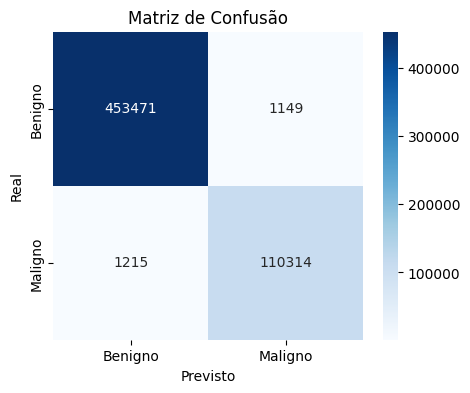

In [6]:
# ===== 4. Gráficos =====
# Matriz de confusão
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Benigno", "Maligno"], yticklabels=["Benigno", "Maligno"])
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de Confusão")
plt.show()

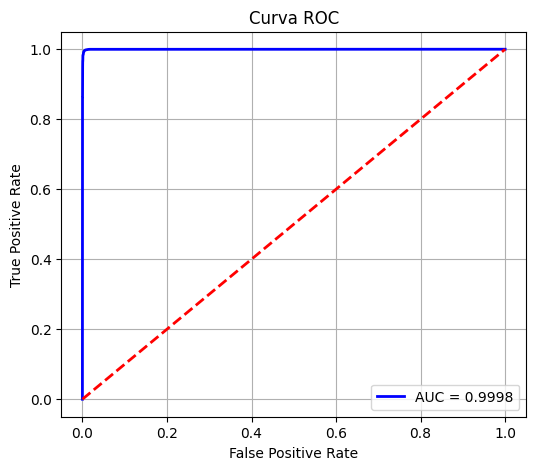

In [7]:
# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color="blue", lw=2, label=f"AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], color="red", lw=2, linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


/var/folders/4z/gqncql5s1j790pb6phf7zx000000gn/T/ipykernel_26754/3896362684.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x="Métrica", y="Valor", palette="viridis")


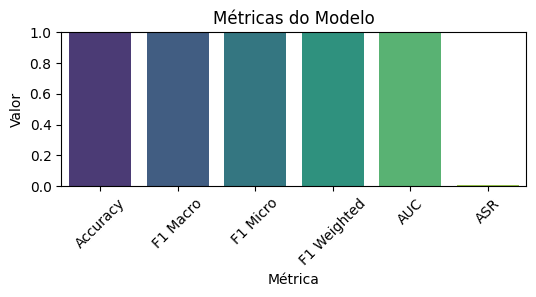

In [8]:
# Tabela de métricas em gráfico
plt.figure(figsize=(6,2))
sns.barplot(data=metrics_df, x="Métrica", y="Valor", palette="viridis")
plt.title("Métricas do Modelo")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.show()
# 

## Comparar vários

In [ ]:
# ===== 2. Preparar lista de modelos =====
models_path = "./models"
model_files = [f for f in os.listdir(models_path) if f.endswith(".joblib")]

results = []

# ===== 3. Loop pelos modelos =====
for model_file in model_files:
    model_name = model_file.replace(".joblib", "")
    model = load(os.path.join(models_path, model_file))
    
    y_pred = model.predict(X)
    
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X)[:, 1]
    else:
        y_prob = model.decision_function(X)
        y_prob = (y_prob - y_prob.min()) / (y_prob.max() - y_prob.min())
    
    accuracy = accuracy_score(y, y_pred)
    f1_macro = f1_score(y, y_pred, average="macro")
    f1_micro = f1_score(y, y_pred, average="micro")
    f1_weighted = f1_score(y, y_pred, average="weighted")
    auc_score = roc_auc_score(y, y_prob)
    asr = np.mean(y_pred[y==1] == 0)
    
    results.append({
        "Modelo": model_name,
        "Accuracy": accuracy,
        "F1 Macro": f1_macro,
        "F1 Micro": f1_micro,
        "F1 Weighted": f1_weighted,
        "AUC": auc_score,
        "ASR": asr
    })

/Users/inespissarra/Downloads/Transformer-based_Adversarial_Network_Traffic_Generator/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
